# Soal 3 — Seleksi Fitur Fisikokimia untuk Memisahkan Kualitas Wine (Genetic Algorithm)

**Nama:** Marsa Naufal  
**NIM:** 04231047  
**Seed:** 47
**Dataset:** D4 — Wine Quality (red wine), UCI
**Library:** `pygad` untuk Genetic Algorithm, `pandas`/`numpy`/`scipy`/`scikit-learn` untuk data dan statistik.


## 1. Business Understanding

**Latar belakang.** Produsen wine ingin tahu kandungan kimia apa saja yang paling membedakan wine berkualitas tinggi dari wine berkualitas rendah. Kalau hal ini diketahui, uji laboratorium bisa difokuskan ke beberapa parameter saja, sehingga lebih murah dan cepat. Ibaratnya seperti dokter yang tidak perlu memeriksa semua organ: cukup beberapa tanda vital yang paling informatif.

**Rumusan masalah.**
1. Dari 11 fitur fisikokimia red wine, subset fitur mana yang paling memisahkan kelompok kualitas tinggi ($q \ge 7$) dan rendah ($q \le 5$) menurut skor $J(S)$?
2. Apakah GA konsisten menemukan subset yang sama bila dijalankan dengan seed berbeda?
3. Apakah fitur yang terpilih memang punya distribusi yang berbeda nyata antara dua kelompok?

**Tujuan.** Menemukan subset fitur dengan $J(S)$ maksimum memakai GA, mengukur kestabilannya, lalu memverifikasinya dengan statistik dan data yang belum pernah dilihat.

**Kriteria kesuksesan** (ditetapkan sebelum eksperimen):

| Kriteria | Ambang |
|---|---|
| GA mencapai nilai $J$ yang sama dengan optimum hasil *brute force* (2¹¹ = 2048 subset) | selisih = 0 |
| Konsistensi antar-run (5 seed) | ≥ 4 dari 5 run menghasilkan subset yang sama |
| Fitur terpilih berbeda signifikan antar-kelompok | uji Mann–Whitney p < 0.05 |
| Subset terpilih tetap memisahkan kelas pada data *hold-out* | balanced accuracy ≥ 0.75 dengan logistic regression sederhana |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygad
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report
from itertools import product

SEED = 47
np.random.seed(SEED)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

## 2. Data Understanding

### 2.1 Memuat data dan melihat sampel
File red wine memakai pemisah titik-koma (`;`). Ditampilkan 20 baris pertama sebagai sampel.

In [2]:
df_raw = pd.read_csv("data/wine+quality/winequality-red.csv", sep=";")
print("Ukuran data:", df_raw.shape)
df_raw.head(20)

Ukuran data: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.600,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.650,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.580,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.500,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


### 2.2 Atribut dan tipe data
Semua fitur numerik kontinu hasil uji lab. `quality` adalah skor 0–10 dari panel pencicip (median dari minimal 3 penilai) dan bertipe integer ordinal.

| Atribut | Arti singkat | Satuan |
|---|---|---|
| fixed acidity | asam tetap (tartarat) | g/dm³ |
| volatile acidity | asam asetat; kalau tinggi, rasanya seperti cuka | g/dm³ |
| citric acid | asam sitrat; memberi kesegaran | g/dm³ |
| residual sugar | gula sisa fermentasi | g/dm³ |
| chlorides | kadar garam | g/dm³ |
| free sulfur dioxide | SO₂ bebas (antimikroba) | mg/dm³ |
| total sulfur dioxide | SO₂ total | mg/dm³ |
| density | massa jenis | g/cm³ |
| pH | keasaman | – |
| sulphates | aditif sulfat (berkaitan dengan SO₂) | g/dm³ |
| alcohol | kadar alkohol | % vol |
| quality | skor kualitas (target) | 0–10 |

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


### 2.3 Statistik deskriptif

In [4]:
df_raw.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


### 2.4 Missing value, duplikasi, dan outlier

In [5]:
print("Missing value per kolom:\n", df_raw.isna().sum().to_string())
print("\nJumlah baris duplikat:", df_raw.duplicated().sum())

feat_all = df_raw.columns.drop("quality").tolist()
q1, q3 = df_raw[feat_all].quantile(0.25), df_raw[feat_all].quantile(0.75)
iqr = q3 - q1
outlier = ((df_raw[feat_all] < q1 - 1.5 * iqr) | (df_raw[feat_all] > q3 + 1.5 * iqr)).sum()
print("\nJumlah outlier (aturan 1.5×IQR) per fitur:\n", outlier.to_string())

Missing value per kolom:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0

Jumlah baris duplikat: 240

Jumlah outlier (aturan 1.5×IQR) per fitur:
 fixed acidity            49
volatile acidity         19
citric acid               1
residual sugar          155
chlorides               112
free sulfur dioxide      30
total sulfur dioxide     55
density                  45
pH                       35
sulphates                59
alcohol                  13


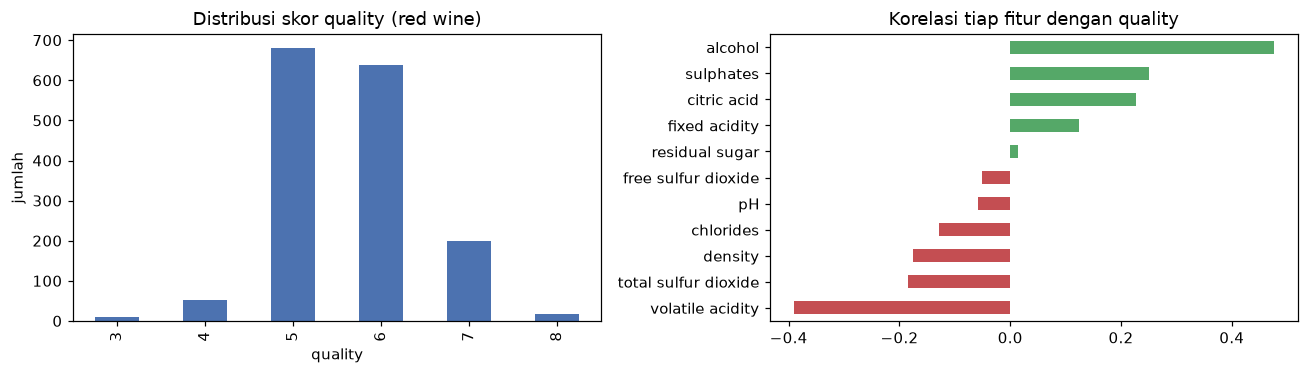

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
df_raw["quality"].value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribusi skor quality (red wine)"); axes[0].set_xlabel("quality"); axes[0].set_ylabel("jumlah")
corr = df_raw.corr()["quality"].drop("quality").sort_values()
corr.plot.barh(ax=axes[1], color=["#C44E52" if v < 0 else "#55A868" for v in corr])
axes[1].set_title("Korelasi tiap fitur dengan quality")
plt.tight_layout(); plt.show()

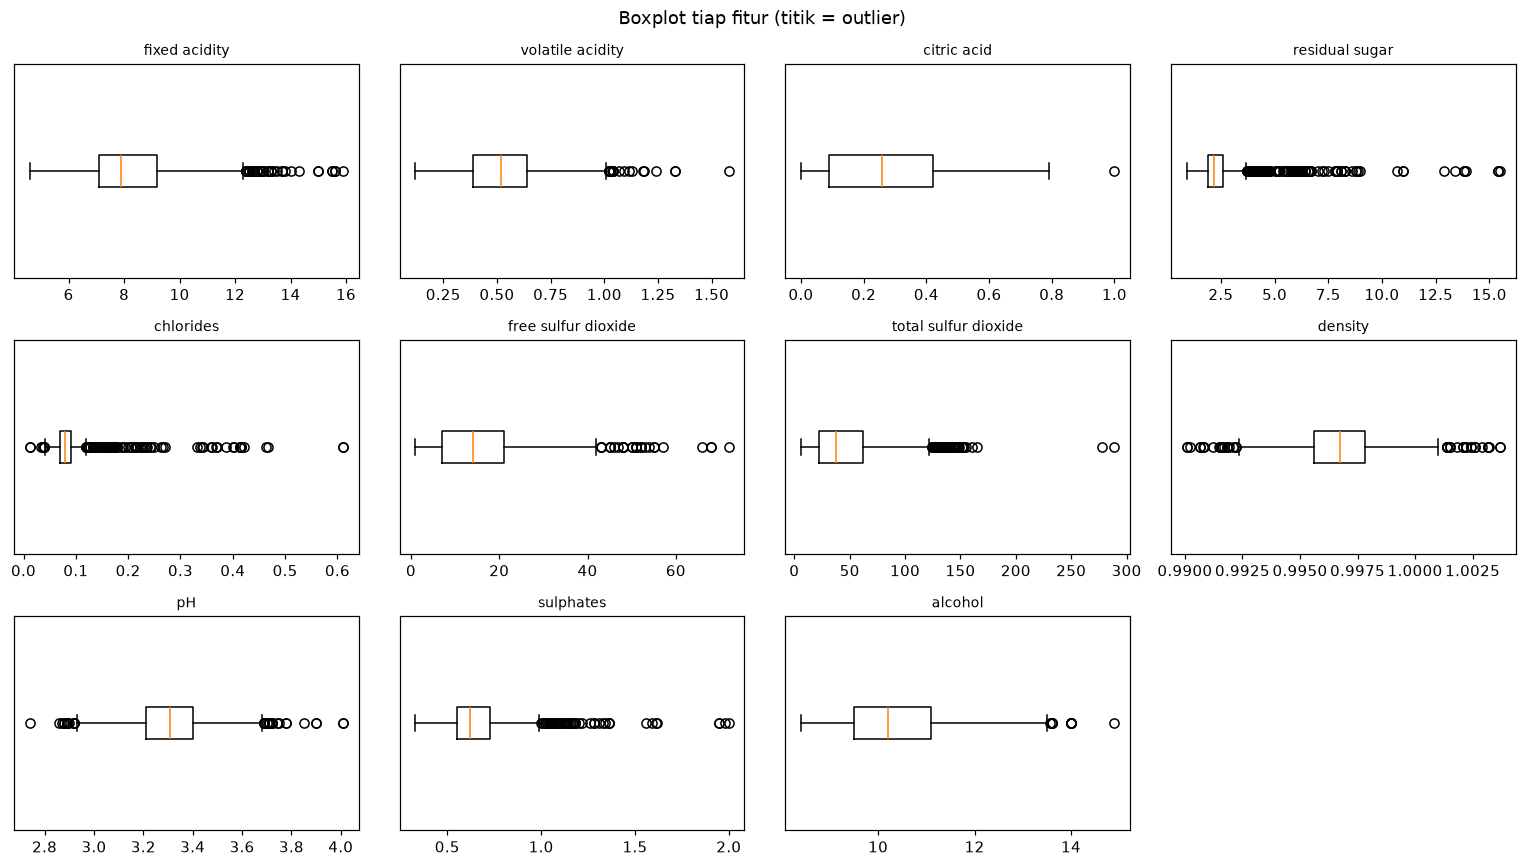

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax, col in zip(axes.flat, feat_all):
    ax.boxplot(df_raw[col], orientation="horizontal"); ax.set_title(col, fontsize=9); ax.set_yticks([])
axes.flat[-1].axis("off")
plt.suptitle("Boxplot tiap fitur (titik = outlier)"); plt.tight_layout(); plt.show()

**Interpretasi Data Understanding.**
- Ada **1599 baris dan 12 kolom**, semuanya numerik, dan **tidak ada missing value**.
- Ada **240 baris duplikat (±15%)**. Jumlah ini cukup besar, jadi perlu ditangani.
- Skor `quality` terkumpul di 5 dan 6. Kualitas sangat rendah (3–4) dan sangat tinggi (8) jarang, jadi setelah pengelompokan kelas H akan menjadi minoritas.
- Outlier terbanyak ada di `residual sugar` (155) dan `chlorides` (112). Boxplot memperlihatkan distribusinya **miring ke kanan** (ekor panjang di nilai besar). Ini wajar untuk data kimia: sebagian kecil wine memang sangat manis atau asin.
- Dari grafik korelasi, `alcohol` paling berhubungan positif dengan kualitas, sedangkan `volatile acidity` paling negatif (asam asetat tinggi = rasa cuka). Ini sudah memberi gambaran awal fitur mana yang kemungkinan dipilih GA.

## 3. Data Preparation

Langkah-langkahnya:
1. **Duplikat dibuang.** Baris yang identik di semua kolom akan dihitung dua kali di rata-rata dan simpangan baku. Kalau satu salinan jatuh ke data latih dan salinan lain ke data uji, data uji tidak lagi benar-benar "baru".
2. **Pelabelan kelompok** sesuai soal: tinggi (H) bila $q \ge 7$, rendah (L) bila $q \le 5$. Sampel $q = 6$ dibuang karena berada di tengah dan membuat batas kelompok kabur.
3. **Outlier tidak dibuang.** Nilai ekstrem seperti sulphates atau chlorides yang tinggi adalah hasil uji lab yang sah, bukan salah input. Efeknya terhadap mean/std tetap diwaspadai, dan di bagian 5 dicek ulang dengan statistik yang tahan outlier (median, Mann–Whitney).
4. **Split 80:20 berstrata (seed 47).** $J(S)$ dan GA hanya dihitung dari data latih. Data *hold-out* 20% disimpan untuk memverifikasi subset terpilih di akhir, supaya pemilihan fitur tidak "mengintip" data uji.
5. **Tanpa scaling untuk $J(S)$.** Rumusnya sudah membagi selisih rata-rata dengan simpangan baku, jadi satuan tiap fitur saling meniadakan. Scaling hanya dipakai untuk logistic regression saat verifikasi.

In [8]:
df = df_raw.drop_duplicates().reset_index(drop=True)
df = df[df["quality"] != 6].copy()
df["kelas"] = np.where(df["quality"] >= 7, "H", "L")
print("Setelah buang duplikat & q=6:", df.shape)
print(df["kelas"].value_counts().to_string())

X = df[feat_all]
y = (df["kelas"] == "H").astype(int)
X_tr, X_ho, y_tr, y_ho = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"\nTrain: {len(X_tr)} (H={y_tr.sum()}),  Hold-out: {len(X_ho)} (H={y_ho.sum()})")

Setelah buang duplikat & q=6: (824, 13)
kelas
L    640
H    184

Train: 659 (H=147),  Hold-out: 165 (H=37)


Data tidak seimbang: kelompok H jauh lebih sedikit dari L. Untuk $J(S)$ ini tidak masalah, karena tiap kelompok diringkas dengan mean dan std-nya sendiri, jadi ukuran kelompok tidak ikut menimbang. Saat verifikasi dengan classifier dipakai `class_weight="balanced"` dan metrik *balanced accuracy* supaya kelas minoritas tidak diabaikan.

## 4. Modeling — Genetic Algorithm

### Jawaban 3a — Makna setiap komponen $J(S)$, penalti, dan kromosom kosong

$$J(S) = \sum_{j \in S} \frac{|\mu_{H,j} - \mu_{L,j}|}{\sigma_{H,j} + \sigma_{L,j} + \varepsilon} - 0.10\,|S|$$

| Komponen | Makna |
|---|---|
| $\lvert\mu_{H,j} - \mu_{L,j}\rvert$ | Seberapa jauh rata-rata fitur $j$ antara wine bagus dan wine jelek. Makin jauh, makin membedakan. |
| $\sigma_{H,j} + \sigma_{L,j}$ | Seberapa "menyebar" nilai di tiap kelompok. Selisih rata-rata 1 tidak berarti apa-apa kalau datanya menyebar ±10, tapi sangat berarti kalau menyebarnya hanya ±0.1. Pembagi ini menjadikan skor tanpa satuan, mirip *signal-to-noise ratio*. |
| $\varepsilon$ | Angka sangat kecil (1e-9) supaya tidak terjadi pembagian dengan nol bila std = 0. |
| $-0.10\lvert S\rvert$ | Penalti 0.10 per fitur yang dipakai. |

**Kenapa perlu penalti?** Setiap suku pemisahan bernilai ≥ 0, jadi tanpa penalti menambah fitur tidak pernah menurunkan $J$, dan solusi terbaik selalu "pakai semua fitur". Penalti membuat sebuah fitur hanya layak masuk kalau skor pemisahannya lebih dari 0.10. Ibaratnya tiket masuk: fitur yang kontribusinya kurang dari harga tiket tidak diajak. Hasilnya subset yang ringkas, murah diukur, dan lebih mudah dijelaskan.

**Kromosom kosong** (semua gen 0) berarti tidak ada fitur sama sekali. Secara rumus $J = 0$, padahal subset kosong tidak bisa memisahkan apa pun. Karena itu kromosom kosong diberi **fitness −10**, jauh di bawah subset valid mana pun (nilai terendah subset valid adalah −0.10 × 11 = −1.1). Dengan begitu kromosom kosong tidak akan terpilih sebagai orang tua dan cepat hilang dari populasi.

**Catatan penting:** $J(S)$ adalah jumlah skor per fitur, dan tiap fitur tidak saling mempengaruhi. Artinya jawaban optimal bisa dihitung langsung (ambil semua fitur dengan skor > 0.10), dan karena hanya ada 2¹¹ = 2048 subset, *brute force* juga mudah. Optimum *brute force* ini dipakai sebagai kunci jawaban untuk memeriksa apakah GA benar-benar menemukan optimum.

In [9]:
mu_H, mu_L = X_tr[y_tr == 1].mean(), X_tr[y_tr == 0].mean()
sd_H, sd_L = X_tr[y_tr == 1].std(), X_tr[y_tr == 0].std()
EPS = 1e-9
score_j = ((mu_H - mu_L).abs() / (sd_H + sd_L + EPS)).values   # skor pemisahan per fitur
PENALTY = 0.10

def J(mask):
    mask = np.asarray(mask, dtype=int)
    if mask.sum() == 0:
        return -10.0          # kromosom kosong: dihukum berat
    return score_j[mask == 1].sum() - PENALTY * mask.sum()

tabel_skor = pd.DataFrame({"mean_H": mu_H, "mean_L": mu_L, "std_H": sd_H, "std_L": sd_L,
                           "skor_pemisahan": score_j, "kontribusi_bersih (skor-0.10)": score_j - PENALTY})
tabel_skor.sort_values("skor_pemisahan", ascending=False).round(4)

,mean_H,mean_L,std_H,std_L,skor_pemisahan,kontribusi_bersih (skor-0.10)
alcohol,11.6515,9.9365,0.9900,0.7892,0.9639,0.8639
volatile acidity,0.4062,0.5931,0.1393,0.1859,0.5746,0.4746
sulphates,0.7426,0.6187,0.1287,0.1773,0.4048,0.3048
citric acid,0.3724,0.2312,0.1931,0.1822,0.3762,0.2762
density,0.9958,0.9970,0.0022,0.0016,0.3066,0.2066
total sulfur dioxide,37.3129,54.9619,36.9835,36.9144,0.2388,0.1388
chlorides,0.0752,0.0941,0.0298,0.0563,0.2204,0.1204
fixed acidity,8.7476,8.1045,1.9468,1.5203,0.1855,0.0855
residual sugar,2.7612,2.5312,1.4509,1.3847,0.0811,-0.0189
free sulfur dioxide,14.8299,16.5293,10.8212,10.5622,0.0795,-0.0205


In [10]:
# Kunci jawaban: brute force semua 2^11 subset
all_masks = np.array(list(product([0, 1], repeat=len(feat_all))))
all_J = np.array([J(m) for m in all_masks])
best_bf = all_masks[all_J.argmax()]
print("Optimum brute force J =", round(all_J.max(), 4))
print("Subset optimum:", [f for f, b in zip(feat_all, best_bf) if b])

Optimum brute force J = 2.4708
Subset optimum: ['fixed acidity', 'volatile acidity', 'citric acid', 'chlorides', 'total sulfur dioxide', 'density', 'sulphates', 'alcohol']


### Jawaban 3b — Desain GA dan pengaruh *mutation rate*

| Komponen | Pilihan | Alasan |
|---|---|---|
| Representasi | biner, 11 gen (1 = fitur dipakai) | sesuai soal, satu gen = satu saklar fitur |
| Ukuran populasi | 30 | ruang solusi hanya 2048, jadi 30 individu sudah cukup beragam |
| Generasi | 50 | cukup untuk konvergen (dilihat di kurva) |
| Seleksi orang tua | *tournament* (k = 3) | yang terbaik dari 3 individu acak; tekanan seleksi sedang, jadi tidak terlalu cepat seragam |
| Crossover | *uniform*, peluang 0.9 | tiap gen diwarisi acak dari salah satu orang tua; cocok karena urutan fitur tidak bermakna (beda dengan single-point yang mengandalkan gen bertetangga) |
| Mutasi | *random* pada `gene_space=[0,1]`, peluang 0.10 per gen | gen yang termutasi diisi ulang 0/1 secara acak, jadi peluang benar-benar terbalik ≈ 0.05 per gen |
| Elitisme | 2 individu terbaik langsung lolos | solusi terbaik tidak pernah hilang |
| Kromosom kosong | fitness −10 | lihat Jawaban 3a |

**Cara kerja di dalam `pygad`, singkatnya:** tiap generasi `pygad` menghitung fitness semua individu, memilih orang tua lewat turnamen, menyilangkan pasangan orang tua gen demi gen (*uniform*), lalu memutasi sebagian gen secara acak. Dua individu terbaik generasi lama ikut ke generasi baru. Siklus ini diulang 50 kali.

**Pengaruh *mutation rate* terhadap eksplorasi.** Mutasi itu seperti "rasa penasaran" populasi.
- *Mutation rate* **terlalu kecil**: anak hampir selalu hanya gabungan gen orang tua. Kalau sebuah fitur penting kebetulan tidak ada di populasi awal, ia sulit muncul kembali. Populasi cepat seragam (konvergensi prematur) dan bisa terjebak di subset yang kurang optimal.
- *Mutation rate* **terlalu besar**: anak hampir seperti individu acak baru, sehingga pencarian berubah menjadi *random search* dan solusi bagus sering rusak. Elitisme menahan agar yang terbaik tidak hilang, tapi rata-rata populasi tetap buruk.
- **Nilai sedang** memberi keseimbangan: populasi masih mengeksplorasi subset baru sambil tetap memperbaiki solusi yang sudah bagus.

Klaim ini diuji di bawah dengan beberapa *mutation rate* (masing-masing 5 seed). Yang diukur: generasi saat optimum pertama kali ditemukan, rata-rata fitness populasi akhir, dan keragaman populasi (rata-rata jarak Hamming antar-individu).

In [ ]:
def fitness_func(ga, solution, idx):
    return J(solution)

def run_ga(seed, mutation_prob=0.10, generations=50, verbose=False):
    hist = {"best": [], "mean": [], "div": []}

    def record(pop):
        fit = np.array([J(s) for s in pop])
        hist["best"].append(fit.max()); hist["mean"].append(fit.mean())
        diff = (pop[:, None, :] != pop[None, :, :]).sum(-1)          # jarak Hamming antar individu
        hist["div"].append(diff[np.triu_indices(len(pop), 1)].mean())

    ga = pygad.GA(num_generations=generations, num_parents_mating=10, fitness_func=fitness_func,
                  sol_per_pop=30, num_genes=len(feat_all), gene_type=int, gene_space=[0, 1],
                  parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", crossover_probability=0.9,
                  mutation_type="random", mutation_probability=mutation_prob,
                  keep_elitism=2, random_seed=seed, suppress_warnings=True,
                  on_start=lambda g: record(g.population.copy()),
                  on_generation=lambda g: record(g.population.copy()))
    ga.run()
    sol, fit, _ = ga.best_solution(ga.last_generation_fitness)
    return np.asarray(sol, dtype=int), fit, hist

In [12]:
mut_rates = [0.01, 0.05, 0.10, 0.30, 0.60]
rows = []
for p in mut_rates:
    for s in range(SEED, SEED + 5):
        sol, fit, h = run_ga(s, mutation_prob=p)
        hit = np.where(np.isclose(h["best"], all_J.max()))[0]
        rows.append({"mutation_prob": p, "seed": s, "capai_optimum": len(hit) > 0,
                     "generasi_capai_optimum": hit[0] if len(hit) else np.nan,
                     "mean_fitness_akhir": h["mean"][-1], "keragaman_akhir": h["div"][-1]})
mut_df = pd.DataFrame(rows)
mut_df.groupby("mutation_prob").agg(run_capai_optimum=("capai_optimum", "sum"),
                                    rata2_generasi_capai=("generasi_capai_optimum", "mean"),
                                    mean_fitness_akhir=("mean_fitness_akhir", "mean"),
                                    keragaman_akhir=("keragaman_akhir", "mean")).round(3)

,run_capai_optimum,rata2_generasi_capai,mean_fitness_akhir,keragaman_akhir
mutation_prob,,,,
0.01,5,5.2,2.438,0.330
0.05,5,4.4,2.335,1.233
0.10,5,4.4,2.135,3.041
0.30,5,8.2,1.597,5.152
0.60,2,6.5,1.204,5.522


**Hasil eksperimen *mutation rate*** (5 seed per nilai, 50 generasi):

- **0.01**: kelima run tetap mencapai optimum, tapi keragaman akhir hanya **0.33**. Artinya hampir semua individu sudah kembar, populasi sudah "berhenti berpikir". Di soal ini masih aman karena ruang solusinya kecil dan populasi awal 30 individu sudah memuat semua gen penting. Pada masalah yang lebih besar, kondisi ini rawan konvergensi prematur.
- **0.05–0.10**: optimum ditemukan paling cepat (rata-rata **generasi ke-4,4**), dan populasi masih cukup beragam (1.2–3.0 bit berbeda antar-individu). Inilah keseimbangan eksplorasi–eksploitasi yang dicari, jadi **0.10 dipakai untuk GA utama**.
- **0.30**: masih selalu mencapai optimum, tapi lebih lambat (generasi ke-8,2) dan rata-rata fitness populasi turun ke 1.60 karena banyak anak "dirusak" mutasi.
- **0.60**: hanya **2 dari 5 run** yang mencapai optimum. GA berubah menjadi hampir *random search*: keragaman tinggi (5.5 dari 11 bit, mendekati populasi acak) tetapi solusi bagus tidak sempat dikembangkan.

Kesimpulannya, mutasi terlalu kecil membuat populasi cepat seragam, sedangkan mutasi terlalu besar membuat pencarian acak. Nilai sedang adalah yang paling efisien.

### 4.1 Menjalankan GA utama (seed 47)

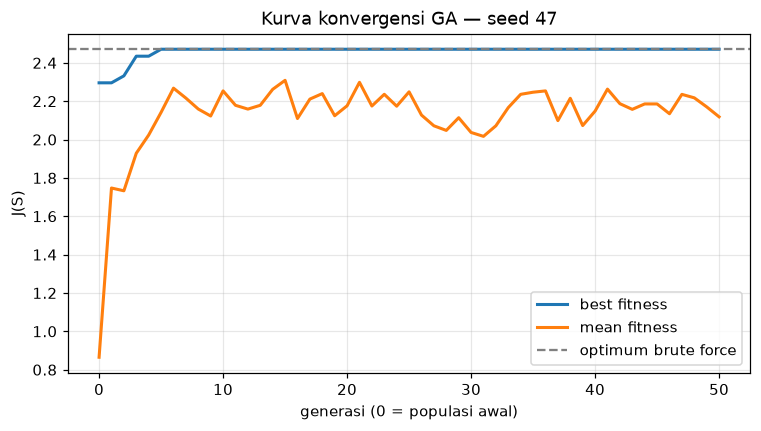

Subset terbaik: ['fixed acidity', 'volatile acidity', 'citric acid', 'chlorides', 'total sulfur dioxide', 'density', 'sulphates', 'alcohol']
J terbaik GA  = 2.4708 | optimum brute force = 2.4708


In [13]:
best_sol, best_fit, hist = run_ga(SEED)
plt.figure(figsize=(8, 4))
plt.plot(hist["best"], label="best fitness", lw=2)
plt.plot(hist["mean"], label="mean fitness", lw=2)
plt.axhline(all_J.max(), ls="--", c="gray", label="optimum brute force")
plt.xlabel("generasi (0 = populasi awal)"); plt.ylabel("J(S)"); plt.title("Kurva konvergensi GA — seed 47")
plt.legend(); plt.grid(alpha=.3); plt.show()
print("Subset terbaik:", [f for f, b in zip(feat_all, best_sol) if b])
print("J terbaik GA  =", round(best_fit, 4), "| optimum brute force =", round(all_J.max(), 4))

## 5. Evaluation

### Jawaban 3c — GA dijalankan 5 kali (seed 47–51)

In [14]:
run_rows, sols = [], []
for s in range(SEED, SEED + 5):
    sol, fit, _ = run_ga(s)
    sols.append(sol)
    run_rows.append({"seed": s, "jumlah_fitur": sol.sum(), "J": round(fit, 4),
                     "sama_dengan_optimum": bool((sol == best_bf).all()),
                     "subset": ", ".join(f for f, b in zip(feat_all, sol) if b)})
runs = pd.DataFrame(run_rows)
runs

,seed,jumlah_fitur,J,sama_dengan_optimum,subset
0,47,8,2.4708,True,"fixed acidity, volatile acidity, citric acid, ..."
1,48,8,2.4708,True,"fixed acidity, volatile acidity, citric acid, ..."
2,49,8,2.4708,True,"fixed acidity, volatile acidity, citric acid, ..."
3,50,8,2.4708,True,"fixed acidity, volatile acidity, citric acid, ..."
4,51,8,2.4708,True,"fixed acidity, volatile acidity, citric acid, ..."


,frekuensi (dari 5 run),skor_pemisahan
alcohol,5,0.9639
volatile acidity,5,0.5746
sulphates,5,0.4048
citric acid,5,0.3762
density,5,0.3066
total sulfur dioxide,5,0.2388
chlorides,5,0.2204
fixed acidity,5,0.1855
residual sugar,0,0.0811
free sulfur dioxide,0,0.0795


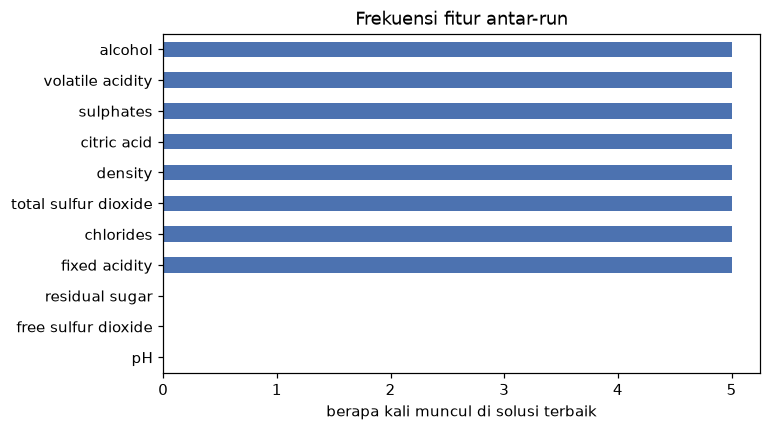

In [15]:
freq = pd.Series(np.array(sols).sum(0), index=feat_all, name="frekuensi (dari 5 run)")
freq_tab = pd.DataFrame({"frekuensi (dari 5 run)": freq, "skor_pemisahan": score_j.round(4)}).sort_values(
    ["frekuensi (dari 5 run)", "skor_pemisahan"], ascending=False)
display(freq_tab)
freq_tab["frekuensi (dari 5 run)"].plot.barh(figsize=(7, 4), color="#4C72B0")
plt.gca().invert_yaxis(); plt.xlabel("berapa kali muncul di solusi terbaik"); plt.title("Frekuensi fitur antar-run")
plt.show()

**Hasil Jawaban 3c.**
- Kelima run (seed 47–51) menghasilkan **subset yang persis sama**, yaitu 8 fitur: *alcohol, volatile acidity, sulphates, citric acid, density, total sulfur dioxide, chlorides, fixed acidity*, dengan **J = 2.4708**. Nilai ini **sama persis dengan optimum *brute force***, jadi GA terbukti menemukan solusi global, bukan sekadar solusi yang "lumayan".
- Kurva konvergensi seed 47 menunjukkan *best fitness* sudah mencapai optimum di **generasi ke-5**. *Mean fitness* naik tajam dari 0.86 (populasi acak) ke kisaran 2.1–2.3, lalu naik-turun di bawah *best*. Celah antara *best* dan *mean* adalah efek mutasi yang terus menciptakan variasi baru, dan ini memang disengaja agar populasi tidak seragam.
- **Frekuensi fitur**: 8 fitur muncul 5/5 kali, sedangkan *residual sugar, free sulfur dioxide,* dan *pH* muncul 0/5 kali. Penyebabnya jelas dari tabel skor: ketiganya punya skor pemisahan 0.06–0.08, **di bawah penalti 0.10**, sehingga memasukkannya justru menurunkan $J$.
- **Kenapa sangat stabil?** Seperti dijelaskan di Jawaban 3a, $J(S)$ bisa dipecah per fitur dan ruang solusinya kecil (2048), sehingga *landscape*-nya mudah dan tidak punya jebakan optimum lokal. Fitur yang paling "tipis" lolosnya adalah *fixed acidity* (skor 0.185, hanya 0.085 di atas penalti). Kalau penalti dinaikkan ke ~0.19, fitur inilah yang pertama keluar.

### Jawaban 3d — Apakah fitur yang sering dipilih benar-benar memisahkan distribusi?

Skor $J$ hanya melihat mean dan std, padahal mean sensitif terhadap outlier dan distribusi bisa miring. Jadi dicek dengan cara lain:
1. **Plot distribusi** (histogram berdensitas) H vs L untuk fitur yang terpilih, ditambah satu fitur yang tidak terpilih sebagai pembanding.
2. **Uji Mann–Whitney U**: membandingkan peringkat nilai, bukan mean, sehingga tahan outlier dan tidak mengasumsikan distribusi normal.
3. **Kolmogorov–Smirnov (KS)**: jarak terbesar antara dua kurva distribusi kumulatif (0 = identik, 1 = terpisah total).
4. **Selisih median** dan **AUC satu fitur**: peluang wine H acak punya nilai lebih tinggi (atau lebih rendah) dari wine L acak; 0.5 berarti tidak membedakan.

In [16]:
rows = []
for f in feat_all:
    a, b = X_tr.loc[y_tr == 1, f], X_tr.loc[y_tr == 0, f]
    u, p_u = stats.mannwhitneyu(a, b)
    ks, p_ks = stats.ks_2samp(a, b)
    auc = u / (len(a) * len(b))
    rows.append({"fitur": f, "terpilih": bool(best_bf[feat_all.index(f)]), "skor_J": score_j[feat_all.index(f)],
                 "median_H": a.median(), "median_L": b.median(), "AUC_1fitur": max(auc, 1 - auc),
                 "KS": ks, "p_MannWhitney": p_u})
stat_tab = pd.DataFrame(rows).sort_values("skor_J", ascending=False).reset_index(drop=True)
stat_tab.round(3).assign(p_MannWhitney=stat_tab["p_MannWhitney"].map("{:.2e}".format))

,fitur,terpilih,skor_J,median_H,median_L,AUC_1fitur,KS,p_MannWhitney
0,alcohol,True,0.964,11.700,9.700,0.912,0.691,1.37e-52
1,volatile acidity,True,0.575,0.380,0.590,0.803,0.492,3.63e-29
2,sulphates,True,0.405,0.740,0.580,0.795,0.521,7.95e-28
3,citric acid,True,0.376,0.390,0.220,0.709,0.444,1.00e-14
4,density,True,0.307,0.996,0.997,0.679,0.368,3.56e-11
5,total sulfur dioxide,True,0.239,28.000,46.000,0.664,0.278,1.28e-09
6,chlorides,True,0.220,0.071,0.082,0.683,0.337,1.34e-11
7,fixed acidity,True,0.185,8.700,7.800,0.619,0.224,1.11e-05
8,residual sugar,False,0.081,2.300,2.200,0.544,0.089,1.06e-01
9,free sulfur dioxide,False,0.079,12.000,15.000,0.560,0.124,2.66e-02


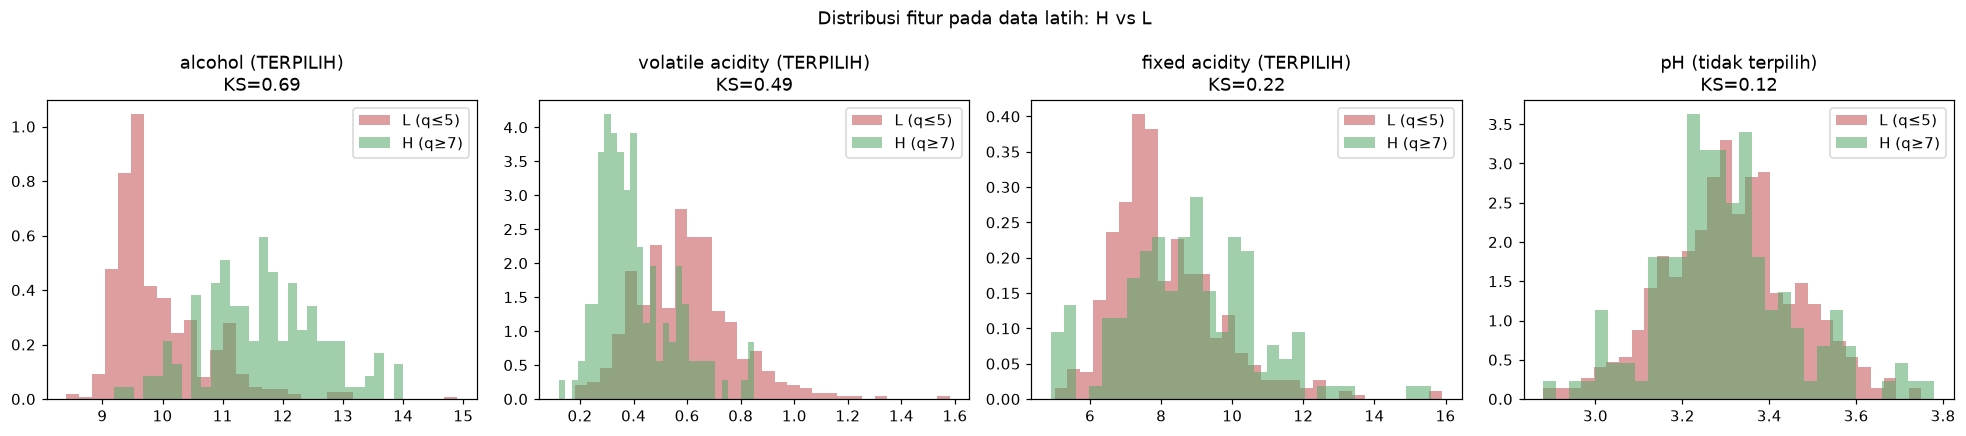

In [17]:
chosen = [f for f, b in zip(feat_all, best_bf) if b]
terpilih_urut = stat_tab[stat_tab["terpilih"]]["fitur"].tolist()
# 2 fitur terpilih terkuat, 1 fitur terpilih terlemah, 1 fitur tidak terpilih terlemah
plot_feats = terpilih_urut[:2] + [terpilih_urut[-1], stat_tab[~stat_tab["terpilih"]]["fitur"].iloc[-1]]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, plot_feats):
    ax.hist(X_tr.loc[y_tr == 0, f], bins=30, density=True, alpha=.55, label="L (q≤5)", color="#C44E52")
    ax.hist(X_tr.loc[y_tr == 1, f], bins=30, density=True, alpha=.55, label="H (q≥7)", color="#55A868")
    tag = "TERPILIH" if f in chosen else "tidak terpilih"
    ax.set_title(f"{f} ({tag})\nKS={stat_tab.set_index('fitur').loc[f,'KS']:.2f}"); ax.legend()
plt.suptitle("Distribusi fitur pada data latih: H vs L"); plt.tight_layout(); plt.show()

Skor $J$ menilai tiap fitur **sendiri-sendiri**, jadi tidak tahu kalau dua fitur sebenarnya membawa informasi yang sama. Karena itu korelasi antar-fitur terpilih juga dicek.

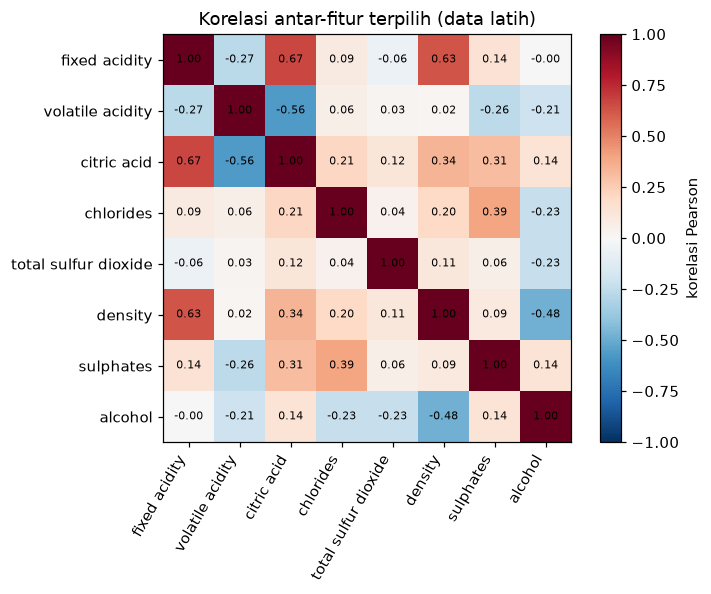

In [18]:
corr_sel = X_tr[chosen].corr()
plt.figure(figsize=(7, 5.5))
plt.imshow(corr_sel, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar(label="korelasi Pearson")
plt.xticks(range(len(chosen)), chosen, rotation=60, ha="right"); plt.yticks(range(len(chosen)), chosen)
for i in range(len(chosen)):
    for j in range(len(chosen)):
        plt.text(j, i, f"{corr_sel.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Korelasi antar-fitur terpilih (data latih)"); plt.tight_layout(); plt.show()

**Verifikasi di data *hold-out*.** Kalau subset terpilih memang informatif, model sederhana yang hanya memakai subset itu seharusnya hampir sebaik model yang memakai semua fitur, ketika diuji pada data yang tidak ikut menghitung $J$. Logistic regression dipakai di sini hanya sebagai alat ukur, bukan bagian dari jawaban GA.

In [19]:
def eval_subset(cols):
    sc = StandardScaler().fit(X_tr[cols])
    clf = LogisticRegression(class_weight="balanced", max_iter=1000).fit(sc.transform(X_tr[cols]), y_tr)
    pred = clf.predict(sc.transform(X_ho[cols]))
    return balanced_accuracy_score(y_ho, pred), pred

ver = []
for name, cols in [("Subset GA", chosen), ("Semua 11 fitur", feat_all),
                   ("Subset GA tanpa fitur skor tertinggi", [c for c in chosen if c != stat_tab.loc[0, "fitur"]]),
                   ("3 fitur skor tertinggi saja", terpilih_urut[:3])]:
    ba, _ = eval_subset(cols)
    ver.append({"skenario": name, "jumlah_fitur": len(cols), "balanced_accuracy_holdout": round(ba, 4)})
pd.DataFrame(ver)

,skenario,jumlah_fitur,balanced_accuracy_holdout
0,Subset GA,8,0.8255
1,Semua 11 fitur,11,0.8216
2,Subset GA tanpa fitur skor tertinggi,7,0.8156
3,3 fitur skor tertinggi saja,3,0.8024


**Hasil Jawaban 3d.**

1. **Fitur terkuat benar-benar terpisah.** Pada `alcohol`, median wine H 11.7% vs L 9.7%, KS = 0.69, dan AUC satu fitur 0.91. Artinya kalau diambil satu wine H dan satu wine L secara acak, 91% kemungkinan wine H punya alkohol lebih tinggi. Pada histogram, kedua distribusi hampir tidak bertumpuk. `volatile acidity` juga jelas: median H 0.38 vs L 0.59, KS = 0.49, dan wine bagus cenderung asam asetatnya rendah.
2. **Semua 8 fitur terpilih signifikan** pada uji Mann–Whitney (p terbesar 1.1×10⁻⁵ untuk *fixed acidity*). Arah median juga sama dengan arah mean, jadi hasil $J$ tidak sekadar terbawa outlier.
3. **Tapi tidak semua sama kuat.** *Fixed acidity* (KS 0.22, AUC 0.62) dan *total sulfur dioxide* (KS 0.28) distribusinya masih banyak bertumpuk, terlihat di plot ketiga. Signifikan secara statistik belum tentu kuat secara praktis; dengan ratusan sampel, perbedaan kecil pun bisa signifikan.
4. **Fitur yang tidak dipilih memang lemah.** *pH* (KS 0.12, p = 0.065) dan *residual sugar* (p = 0.106) tidak signifikan, dan histogram pH H vs L hampir identik. *Free sulfur dioxide* signifikan (p = 0.027) tetapi efeknya sangat kecil (AUC 0.56), jadi wajar dibuang oleh penalti.
5. **Kelemahan $J(S)$: redundansi.** Peta korelasi memperlihatkan *fixed acidity* berkorelasi 0.67 dengan *citric acid* dan 0.63 dengan *density*, dan *density* berkorelasi −0.48 dengan *alcohol* (alkohol lebih ringan dari air). $J$ menjumlahkan skor tiap fitur seolah-olah informasinya terpisah, padahal sebagian "bercerita hal yang sama". Buktinya di data *hold-out*:
   - 8 fitur GA: balanced accuracy **0.826**; semua 11 fitur: **0.822**. Membuang 3 fitur tidak merugikan.
   - Hanya **3 fitur teratas** (alcohol, volatile acidity, sulphates): **0.802**. Hanya turun 0.02 padahal fiturnya 5 lebih sedikit.
   - 8 fitur tanpa *alcohol*: masih **0.816**, karena *density* ikut membawa informasi alkohol.

**Kesimpulan 3d:** fitur yang sering dipilih memang punya pemisahan distribusi yang nyata, dengan pemisah paling kuat *alcohol*, *volatile acidity*, dan *sulphates*. Namun karena $J(S)$ tidak memperhitungkan korelasi antar-fitur, subset 8 fitur masih mengandung redundansi. Perbaikan yang bisa diusulkan: menambah penalti korelasi antar-fitur terpilih (ide mRMR, *minimum redundancy maximum relevance*), atau memakai fitness berbasis performa classifier di data validasi.

## 6. Interpretasi Hasil

### 6.1 Uji akhir pada data baru (*hold-out*): prediksi vs aktual
Model logistic regression dengan subset fitur hasil GA dipakai untuk menebak kelompok kualitas wine di data *hold-out* yang tidak pernah dipakai saat memilih fitur.

In [20]:
ba, pred = eval_subset(chosen)
print(classification_report(y_ho, pred, target_names=["L (q≤5)", "H (q≥7)"], digits=3))
print("Confusion matrix (baris = aktual L,H; kolom = prediksi L,H):\n", confusion_matrix(y_ho, pred))
contoh = X_ho[chosen].copy()
contoh["aktual"] = np.where(y_ho == 1, "H", "L"); contoh["prediksi"] = np.where(pred == 1, "H", "L")
contoh["benar?"] = contoh["aktual"] == contoh["prediksi"]
contoh.head(20)

              precision    recall  f1-score   support

     L (q≤5)      0.933     0.867     0.899       128
     H (q≥7)      0.630     0.784     0.699        37

    accuracy                          0.848       165
   macro avg      0.782     0.825     0.799       165
weighted avg      0.865     0.848     0.854       165

Confusion matrix (baris = aktual L,H; kolom = prediksi L,H):
 [[111  17]
 [  8  29]]


,fixed acidity,volatile acidity,citric acid,chlorides,total sulfur dioxide,density,sulphates,alcohol,aktual,prediksi,benar?
553,9.5,0.885,0.27,0.084,145.0,0.99780,0.53,9.4,L,L,True
1247,6.7,0.700,0.08,0.067,16.0,0.99334,0.52,12.6,L,H,False
54,7.8,0.590,0.18,0.076,54.0,0.99750,0.59,10.0,L,L,True
753,8.8,0.310,0.40,0.109,16.0,0.99614,0.79,11.8,H,H,True
811,8.2,0.310,0.40,0.058,10.0,0.99536,0.68,11.2,H,H,True
378,12.3,0.390,0.63,0.091,18.0,1.00040,0.49,9.5,L,L,True
559,7.3,0.670,0.05,0.107,20.0,0.99720,0.63,10.1,L,L,True
423,10.6,0.360,0.60,0.152,18.0,0.99860,1.06,9.4,L,H,False
185,11.0,0.300,0.58,0.054,19.0,0.99800,0.88,10.5,H,H,True
1070,7.5,0.590,0.22,0.082,60.0,0.99499,0.42,9.2,L,L,True


**Interpretasi uji akhir.** Dengan 8 fitur hasil GA, model menebak benar **84.8%** wine di data *hold-out* (balanced accuracy **0.826**). Dari 37 wine berkualitas tinggi, 29 terdeteksi (recall H **0.784**). Kesalahan terbanyak ada pada 17 wine biasa yang ditebak "tinggi" (precision H 0.63). Wajar, karena beberapa wine L punya alkohol cukup tinggi dan asam asetat rendah sehingga "terlihat" seperti wine bagus. Contohnya baris 1247 di tabel: alkohol 12.6% tetapi aktualnya L.

### 6.2 Pengecekan kriteria kesuksesan

| Kriteria | Target | Hasil | Status |
|---|---|---|---|
| GA = optimum *brute force* | selisih 0 | J = 2.4708 di kelima run | ✅ |
| Konsistensi antar-run | ≥ 4/5 run sama | 5/5 run sama | ✅ |
| Fitur terpilih signifikan | p < 0.05 | 8/8 fitur p ≤ 1.1×10⁻⁵ | ✅ |
| Separasi di *hold-out* | balanced acc ≥ 0.75 | 0.826 | ✅ |

### 6.3 Kesimpulan
1. GA dengan representasi biner menemukan subset optimal **8 dari 11 fitur** (J = 2.4708), dan hasilnya identik di 5 seed.
2. Stabilitas yang sempurna ini bukan semata kehebatan GA. Penyebab utamanya, fungsi $J(S)$ bisa dipecah per fitur dan ruang solusinya kecil, sehingga GA "pasti" menemukannya. Pada fitness yang lebih rumit (misalnya akurasi classifier), hasilnya kemungkinan tidak sestabil ini.
3. *Mutation rate* sedang (0.05–0.10) paling efisien. Terlalu kecil membuat populasi cepat seragam, terlalu besar membuat pencarian acak dan optimum bisa terlewat.
4. Secara praktis, *alcohol*, *volatile acidity*, dan *sulphates* adalah tiga indikator utama wine bagus. Tiga fitur ini saja sudah mencapai balanced accuracy 0.80, jadi uji lab bisa difokuskan ke sini kalau anggaran terbatas.
5. Kritik utama: $J(S)$ tidak menghukum fitur yang redundan. Untuk pengembangan, fitness perlu memperhitungkan korelasi antar-fitur atau performa model di data validasi.